# Fixed policy, estimated economics and SIMULATED alerts

These cells were executed against the real project outputs. The complete training
and SQL implementation is in the linked source modules. This walkthrough reads and
verifies executed artifacts rather than silently retraining the expensive models.
Home Credit is a consumer-lending proxy; validation is random holdout, never true OOT.


In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image
ROOT=Path.cwd()
if not (ROOT/'reports/metrics.json').exists():
    ROOT=ROOT.parent
metrics=json.loads((ROOT/'reports/metrics.json').read_text())


## Policy selection and outcomes

{
  "selected_using": "Calibration/policy partition only; maximize assumed net benefit subject to minimum approval",
  "assumptions": {
    "label": "ILLUSTRATIVE ESTIMATE - ASSUMPTIONS, NOT OBSERVED INR OUTCOMES",
    "annual_applications": 100000,
    "average_loan_inr": 500000,
    "lgd": 0.6,
    "good_loan_margin": 0.08,
    "minimum_approval_rate": 0.6
  },
  "selected_cutoff": 545.0,
  "evaluation": {
    "train": {
      "cutoff": 545.0,
      "applications": 147604,
      "accepted": 116907,
      "accepted_bads": 5646,
      "rejected_bads": 6270,
      "rejected_goods": 24427,
      "approval_rate": 0.7920313812633804,
      "baseline_bad_rate": 0.08072951952521612,
      "accepted_bad_rate": 0.0482947984295209,
      "relative_bad_rate_reduction": 0.40177027296148016,
      "good_customers_rejected_share": 0.1800232887211839,
      "estimated_annual_gross_loss_avoided_crore": 127.43557085173843,
      "estimated_annual_good_margin_foregone_crore": 66.19603804774938,
      "

,cutoff,applications,accepted,accepted_bads,rejected_bads,rejected_goods,approval_rate,baseline_bad_rate,accepted_bad_rate,relative_bad_rate_reduction,good_customers_rejected_share,estimated_annual_gross_loss_avoided_crore,estimated_annual_good_margin_foregone_crore,estimated_annual_net_benefit_crore
0,400.0,36902,36902,2979,0,0,1.000000,0.080727,0.080727,0.000000,0.000000,0.000000,0.000000,0.000000
1,405.0,36902,36902,2979,0,0,1.000000,0.080727,0.080727,0.000000,0.000000,0.000000,0.000000,0.000000
2,410.0,36902,36902,2979,0,0,1.000000,0.080727,0.080727,0.000000,0.000000,0.000000,0.000000,0.000000
3,415.0,36902,36902,2979,0,0,1.000000,0.080727,0.080727,0.000000,0.000000,0.000000,0.000000,0.000000
4,420.0,36902,36902,2979,0,0,1.000000,0.080727,0.080727,0.000000,0.000000,0.000000,0.000000,0.000000
5,425.0,36902,36902,2979,0,0,1.000000,0.080727,0.080727,0.000000,0.000000,0.000000,0.000000,0.000000
6,430.0,36902,36902,2979,0,0,1.000000,0.080727,0.080727,0.000000,0.000000,0.000000,0.000000,0.000000
7,435.0,36902,36902,2979,0,0,1.000000,0.080727,0.080727,0.000000,0.000000,0.000000,0.000000,0.000000
8,440.0,36902,36902,2979,0,0,1.000000,0.080727,0.080727,0.000000,0.000000,0.000000,0.000000,0.000000
9,445.0,36902,36902,2979,0,0,1.000000,0.080727,0.080727,0.000000,0.000000,0.000000,0.000000,0.000000


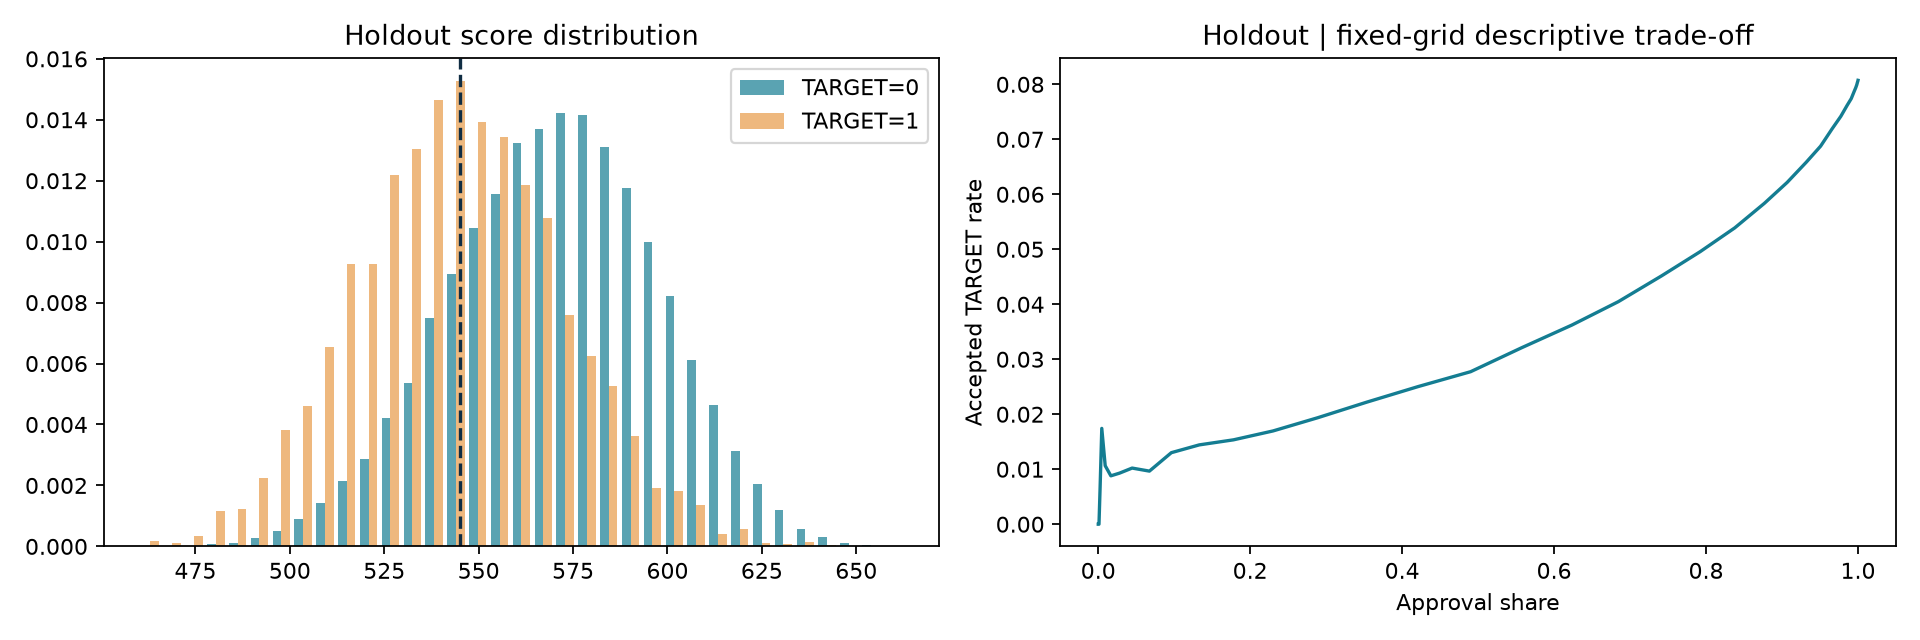

SIMULATED EARLY WARNING - METHOD DEMONSTRATION ONLY
{
  "label": "SIMULATED - METHOD DEMONSTRATION, NOT REAL MERCHANT FINDINGS",
  "borrowers": 2000,
  "daily_rows": 360000,
  "simulated_events": 312,
  "true_positives": 312,
  "false_positives": 373,
  "false_negatives": 0,
  "precision": 0.4554744525547445,
  "recall": 1.0,
  "median_lead_days": 16.0,
  "threshold": 0.25,
  "persistence_days": 3,
  "outcome_definition": "Independent artificial events; real Home Credit TARGET is not used in this simulation."
}


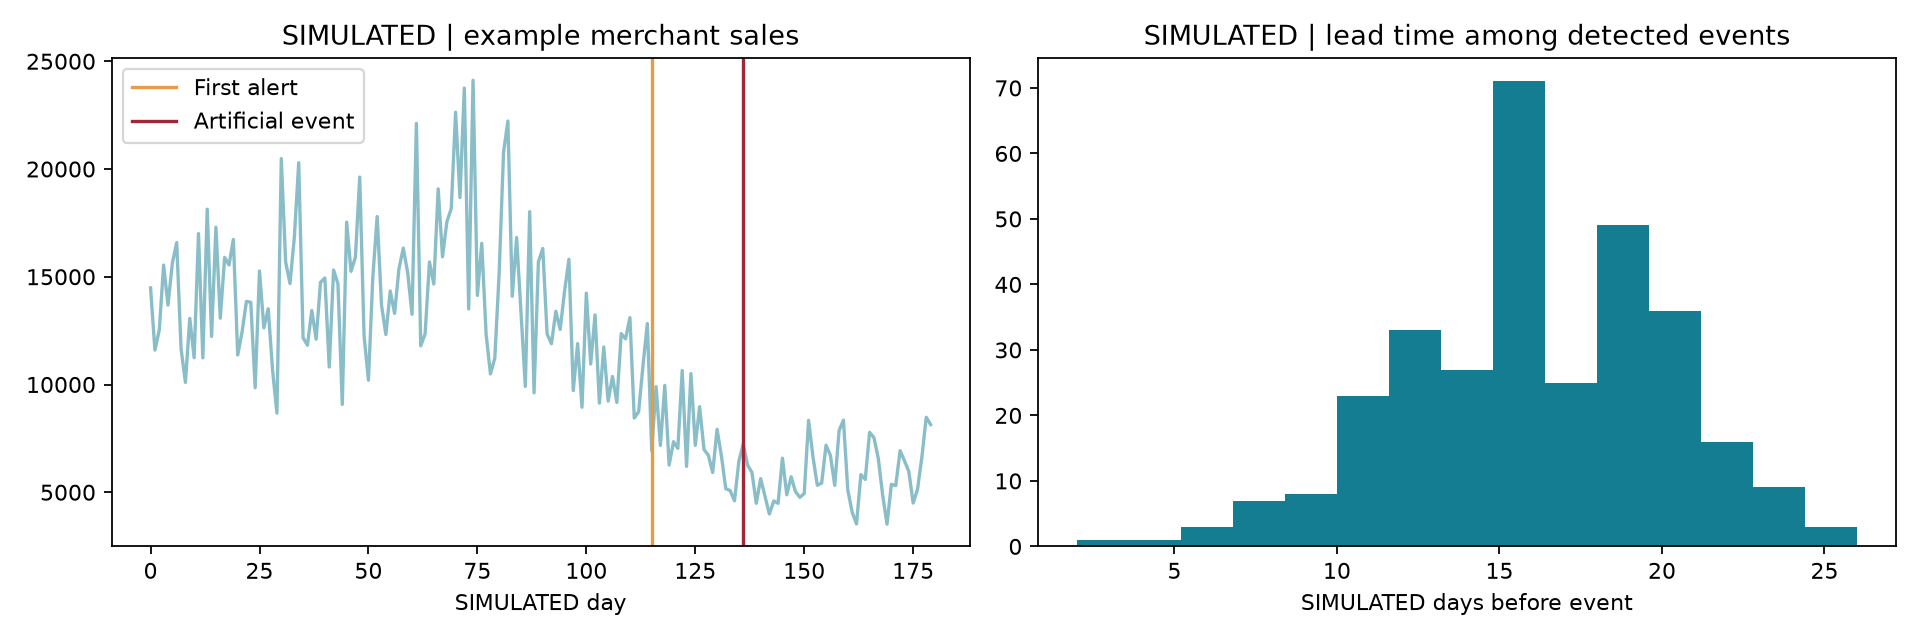

In [2]:
print(json.dumps(metrics['cutoff'],indent=2))
display(pd.read_csv(ROOT/'reports/cutoff_calibration.csv').head(20))
display(Image(filename=str(ROOT/'reports/figures/cutoff_and_distribution.png')))
print('SIMULATED EARLY WARNING - METHOD DEMONSTRATION ONLY')
print(json.dumps(metrics['SIMULATED_early_warning'],indent=2))
display(Image(filename=str(ROOT/'reports/figures/SIMULATED_early_warning.png')))

## Economics and governance

Policy selection uses the reserved policy partition, maximizing illustrative
net benefit with a minimum approval constraint. Holdout metrics are evaluation only.
Bad-rate reduction is relative to the cohort baseline; good rejection share divides
rejected good applicants by all good applicants. Gross loss avoided and net benefit are
different. Edit config/project.json and rerun model stage to change the recommended policy.
All merchant outcomes, dates and sales in the extension are SIMULATED; built-in decline
creates predictability and cannot demonstrate real operational value.